# AFDM: affine frequency division multiplexing

OTFS (`otfs_sim`) separates paths by delay and Doppler by laying the frame out on a **two-dimensional** $M\times N$ lattice. AFDM (Bemani, Ksairi, Kountouris, 2021–2023) achieves the same in a **one-dimensional** frame of $N$ samples, using **chirps** with a tuned slope. The basis is the discrete affine Fourier transform (DAFT):
$$A=\Lambda_{c_2}\,F\,\Lambda_{c_1},\qquad \Lambda_c=\mathrm{diag}\big(e^{-j2\pi c\,n^2}\big),\qquad s=A^Hx,$$
$$s[n]=\frac1{\sqrt N}\sum_m x[m]\,e^{\,j2\pi\left(c_1n^2+c_2m^2+nm/N\right)} .$$
It is a two-parameter family:
- $c_1=c_2=0$ — the DFT, i.e. **OFDM**;
- $c_1=c_2=1/(2N)$ — the Fresnel transform, i.e. **OCDM** (`ocdm_sim`);
- $c_1=\dfrac{2(\alpha_\max+\xi)+1}{2N}$ — **AFDM**: the chirp slope is tuned to the channel's maximum Doppler.

A path with delay $l$ and Doppler $\alpha$ (in bins of $f_s/N$) shifts a symbol in the DAFT domain by $(\alpha-2Nc_1l)\bmod N$. With $2Nc_1>2(\alpha_\max+\xi)$ the Doppler blocks of neighbouring delays **do not overlap**: each path occupies its own samples, the channel is sparse, and the detector gets full diversity — as with OTFS, but without a 2-D grid and with a one-dimensional pilot.

The frame matches `otfs_sim`: $N=1024$ samples at $f_s=0.96$ MHz (a 937.5 Hz Doppler bin), 500 km/h at 4 GHz, 5 paths.

1. DAFT chirps: OFDM, OCDM, AFDM · 2. The chirp-periodic prefix · 3. The channel in the DAFT domain · 4. BER: OFDM, OCDM, AFDM, OTFS on one channel · 5. An embedded pilot in a one-dimensional frame

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N = 1024               # samples per frame (like M·N = 64·16 in otfs_sim)
FS = 0.96e6            # sample rate: Doppler bin f_s/N = 937.5 Hz, as in otfs_sim
FC_GHZ = 4.0
SPEED_KMH = 500
P_PATHS = 5            # delays 0…P−1 samples
XI = 2                 # Doppler margin for the fractional part, bins
FRAMES = 30

rng = np.random.default_rng(SEED)

## Primitives: DAFT, an AFDM modem with CPP, a path-based channel, the effective matrix

In [2]:
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
A_MAX = int(np.ceil(NU_MAX * N / FS))         # maximum Doppler in bins of f_s/N
L_MAX = P_PATHS - 1
L_CP = L_MAX + 4
C1_OPT = (2 * (A_MAX + XI) + 1) / (2 * N)     # Bemani et al.: the shift per delay sample 2N·c1 exceeds the Doppler width
C2 = 0.0
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
n_ = np.arange(N)
F = np.fft.fft(np.eye(N)) / np.sqrt(N)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, n, rng):
    b = rng.integers(0, 2, (B, n, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

def daft(c1, c2=C2):
    """A = Λ_c2 · F · Λ_c1, Λ_c = diag(e^{−j2πcn²}). c1 = c2 = 0 → DFT (OFDM); c1 = c2 = 1/(2N) → the Fresnel transform (OCDM)"""
    lam = lambda c: np.exp(-2j * np.pi * c * n_**2)
    return lam(c2)[:, None] * F * lam(c1)[None, :]

def modulate(x, c1, cp=L_CP, c2=C2):
    """s = Aᴴx + chirp-periodic prefix (CPP): s[n] = s[N+n]·e^{−j2πc1(N² + 2Nn)}, n = −cp…−1"""
    s = x @ daft(c1, c2).conj()                                 # rows of x → Aᴴx
    m = np.arange(-cp, 0)
    return np.concatenate([s[..., N + m] * np.exp(-2j * np.pi * c1 * (N**2 + 2 * N * m)), s], -1)

def demodulate(r, c1, cp=L_CP, c2=C2):
    return r[..., cp:cp + N] @ daft(c1, c2).T

def draw_paths(rng, integer=False):
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * N / FS) * FS / N
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, c1, cp=L_CP):
    return demodulate(channel(modulate(np.eye(N, dtype=complex), c1, cp), paths), c1, cp).T

def lmmse(H, y, n0):
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

# self-checks
assert np.allclose(daft(C1_OPT) @ daft(C1_OPT).conj().T, np.eye(N)), "DAFT unitary"
_b, _x = qpsk_bits(2, N, rng)
assert np.allclose(demodulate(modulate(_x, C1_OPT), C1_OPT), _x)
print(f"N = {N}, f_s = {FS/1e6:.2f} MHz: Doppler bin {FS/N:.1f} Hz, sample {1e6/FS:.2f} µs")
print(f"ν_max = {NU_MAX:.0f} Hz = {NU_MAX*N/FS:.2f} bins → α_max = {A_MAX}; ξ = {XI}; c1 = (2(α_max+ξ)+1)/(2N) = {C1_OPT*2*N:.0f}/(2N), shift per delay sample 2N·c1 = {2*N*C1_OPT:.0f}")
print(f"full-diversity condition (α_max+ξ)(2·l_max+1) + l_max < N: {(A_MAX+XI)*(2*L_MAX+1)+L_MAX} < {N}")

N = 1024, f_s = 0.96 MHz: Doppler bin 937.5 Hz, sample 1.04 µs
ν_max = 1852 Hz = 1.98 bins → α_max = 2; ξ = 2; c1 = (2(α_max+ξ)+1)/(2N) = 9/(2N), shift per delay sample 2N·c1 = 9
full-diversity condition (α_max+ξ)(2·l_max+1) + l_max < N: 40 < 1024


## 1. DAFT chirps
The instantaneous frequency of basis function $m$ is $f[n]=2c_1N\,n+m$ (in bins of $f_s/N$, modulo $N$).
- $c_1=0$ — a horizontal line, a tone: OFDM;
- $c_1=1/(2N)$ — a slope of 1 bin per sample; the band is swept exactly once per symbol: OCDM;
- $c_1=9/(2N)$ — a slope of 9 bins per sample; the chirp "wraps" 9 times per symbol.

The basis is orthonormal for any $c_1$ ($\Lambda$ and $F$ are unitary). The special case $c_1=c_2=1/(2N)$ reduces to the Fresnel matrix of `ocdm_sim`: $A[m,n]\propto e^{-j\pi(m+n)^2/N}$ — the same matrix with a reflected index.

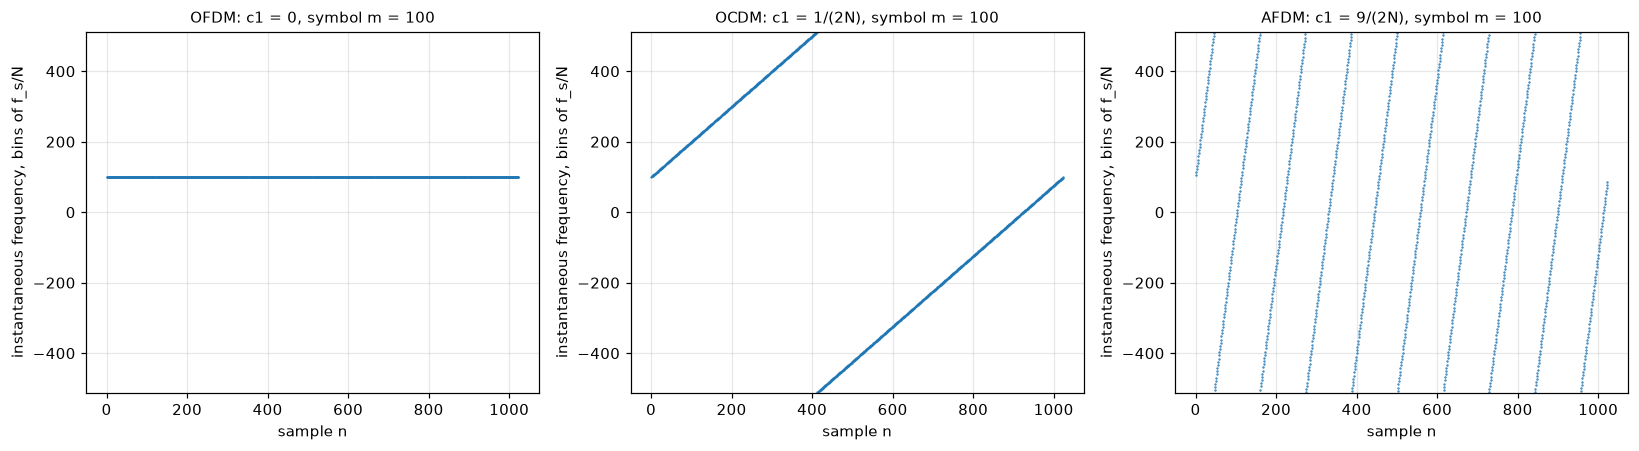

DAFT with c1 = c2 = 1/(2N) is the Fresnel matrix Φ[m,n] = e^(−jπ/4)·e^(jπ(m−n)²/N)/√N with a reflected index and a common phase: phase spread 1.3e-12
Orthogonality of the AFDM chirps: max|⟨φ_m, φ_k⟩ − δ| = 5.0e-16; chirp rate 2c1·N = 9.0000 bins per sample


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
m0 = 100
for a, (c1, name) in zip(ax, ((0.0, "OFDM: c1 = 0"), (1 / (2 * N), "OCDM: c1 = 1/(2N)"), (C1_OPT, f"AFDM: c1 = {2*N*C1_OPT:.0f}/(2N)"))):
    e = np.zeros(N, complex); e[m0] = 1
    s = modulate(e[None], c1, cp=0)[0]
    inst = np.diff(np.unwrap(np.angle(s))) / (2 * np.pi) * N       # instantaneous frequency in bins of f_s/N
    a.plot(n_[1:], (inst + N / 2) % N - N / 2, ".", ms=1)
    a.set_xlabel("sample n"); a.set_ylabel("instantaneous frequency, bins of f_s/N"); a.set_title(f"{name}, symbol m = {m0}", fontsize=10)
    a.set_ylim(-N / 2, N / 2)
plt.tight_layout(); plt.show()

A1 = daft(1 / (2 * N), 1 / (2 * N))
m, nn = np.meshgrid(n_, n_, indexing="ij")
fresnel = np.exp(-1j * np.pi / 4) / np.sqrt(N) * np.exp(1j * np.pi * (m - nn)**2 / N)
ph = A1.conj() / fresnel[:, (-n_) % N]                      # A[m,n] ∝ e^(−jπ(m+n)²/N): Fresnel with the index reflected, n → −n
print(f"DAFT with c1 = c2 = 1/(2N) is the Fresnel matrix Φ[m,n] = e^(−jπ/4)·e^(jπ(m−n)²/N)/√N with a reflected index and a common phase: phase spread {np.ptp(np.angle(ph / ph[0, 0])):.1e}")
G = daft(C1_OPT).conj().T
print(f"Orthogonality of the AFDM chirps: max|⟨φ_m, φ_k⟩ − δ| = {np.max(np.abs(G.conj().T @ G - np.eye(N))):.1e}; chirp rate 2c1·N = {2*C1_OPT*N:.4f} bins per sample")

## 2. The chirp-periodic prefix (CPP)
OFDM needs a CP so that the linear convolution with the channel becomes circular. For that the signal must be periodic: $s[n-N]=s[n]$. A chirp $e^{j2\pi c_1n^2}$ is not by itself periodic with period $N$: a shift by $N$ introduces a factor $e^{-j2\pi c_1(N^2+2Nn)}$. So AFDM uses a **chirp-periodic prefix**
$$s[n]=s[N+n]\,e^{-j2\pi c_1(N^2+2Nn)},\qquad n=-L_\text{cp}\dots-1 .$$
With an integer $2Nc_1$ and even $N$ the factor is 1, and the CPP is the same as a plain CP (our main case, $2Nc_1=9$). With a fractional $2Nc_1$ a plain CP breaks the model: the error is ~2 %, i.e. an SINR floor around −33 dB, while the CPP is exact to machine precision.

With an integer 2N·c1 and even N the CPP factor e^(−j2πc1(N²+2Nn)) = 1 and the CPP equals a plain CP (our case, 2N·c1 = 9). Take a fractional 2N·c1:


  2N·c1 = 9.37, CPP         : model error y = H_eff·x: 1.2e-15
  2N·c1 = 9.37, plain CP    : model error y = H_eff·x: 2.2e-02


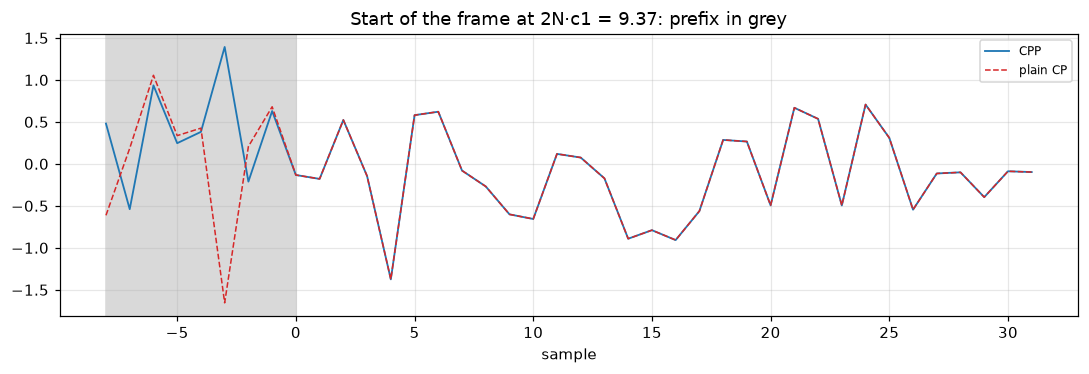

In [4]:
pth = draw_paths(np.random.default_rng(3), integer=True)
_, x = qpsk_bits(1, N, rng)
print(f"With an integer 2N·c1 and even N the CPP factor e^(−j2πc1(N²+2Nn)) = 1 and the CPP equals a plain CP (our case, 2N·c1 = {2*N*C1_OPT:.0f}). Take a fractional 2N·c1:")
c1f = C1_OPT + 0.37 / (2 * N)
H = eff_matrix(pth, c1f)
s_cpp = modulate(x, c1f)
s_cp = s_cpp.copy(); s_cp[:, :L_CP] = s_cpp[:, N:N + L_CP]                  # a plain CP: a copy of the tail without the chirp correction
for s, name in ((s_cpp, "CPP"), (s_cp, "plain CP")):
    y = demodulate(channel(s, pth), c1f)
    print(f"  2N·c1 = {2*N*c1f:.2f}, {name:12}: model error y = H_eff·x: {np.linalg.norm(y - x @ H.T)/np.linalg.norm(y):.1e}")
fig, a = plt.subplots(figsize=(10, 3.5))
t = np.arange(-L_CP, N)
a.plot(t[:40], s_cpp[0, :40].real, "C0", lw=1.2, label="CPP")
a.plot(t[:40], s_cp[0, :40].real, "C3--", lw=1, label="plain CP")
a.axvspan(-L_CP, 0, color="0.85"); a.set_xlabel("sample"); a.legend(fontsize=8)
a.set_title(f"Start of the frame at 2N·c1 = {2*N*c1f:.2f}: prefix in grey")
plt.tight_layout(); plt.show()

## 3. The channel in the DAFT domain
One and the same channel (5 paths, integer Doppler); a column of the effective matrix $H_\text{eff}=AH_\text{time}A^H$ shows where a single symbol goes:
- **OFDM** ($c_1=0$): shift $=\alpha$. Delay does not shift at all, and all paths with the same Doppler **add up** in one sample (here two paths with $\alpha=+1$ merged: 4 nonzeros instead of 5). That is lost diversity;
- **OCDM** ($2Nc_1=1$): shift $=\alpha-l$. Delay and Doppler are coupled, and paths with the same $\alpha-l$ merge. This realization got lucky, but in general it does not;
- **AFDM** ($2Nc_1=9$): shift $=\alpha-9l$. Each delay gets its own window of 9 samples, which holds the whole Doppler range $|\alpha|\le\alpha_\max+\xi=4$. Merging **never happens**.

The frame condition is $(\alpha_\max+\xi)(2l_\max+1)+l_\max<N$, i.e. all the windows must fit into $N$ samples. Here it is 40 out of 1024: a huge margin.

OFDM, c1 = 0          : nonzeros per column    4; path positions (l=0, α=+1) → +1, (l=1, α=+1) → +1, (l=2, α=-2) → -2, (l=3, α=+0) → +0, (l=4, α=+2) → +2


OCDM, c1 = 1/(2N)     : nonzeros per column    5; path positions (l=0, α=+1) → +1, (l=1, α=+1) → +0, (l=2, α=-2) → -4, (l=3, α=+0) → -3, (l=4, α=+2) → -2


AFDM, c1 = 9/(2N)     : nonzeros per column    5; path positions (l=0, α=+1) → +1, (l=1, α=+1) → -8, (l=2, α=-2) → -20, (l=3, α=+0) → -27, (l=4, α=+2) → -34


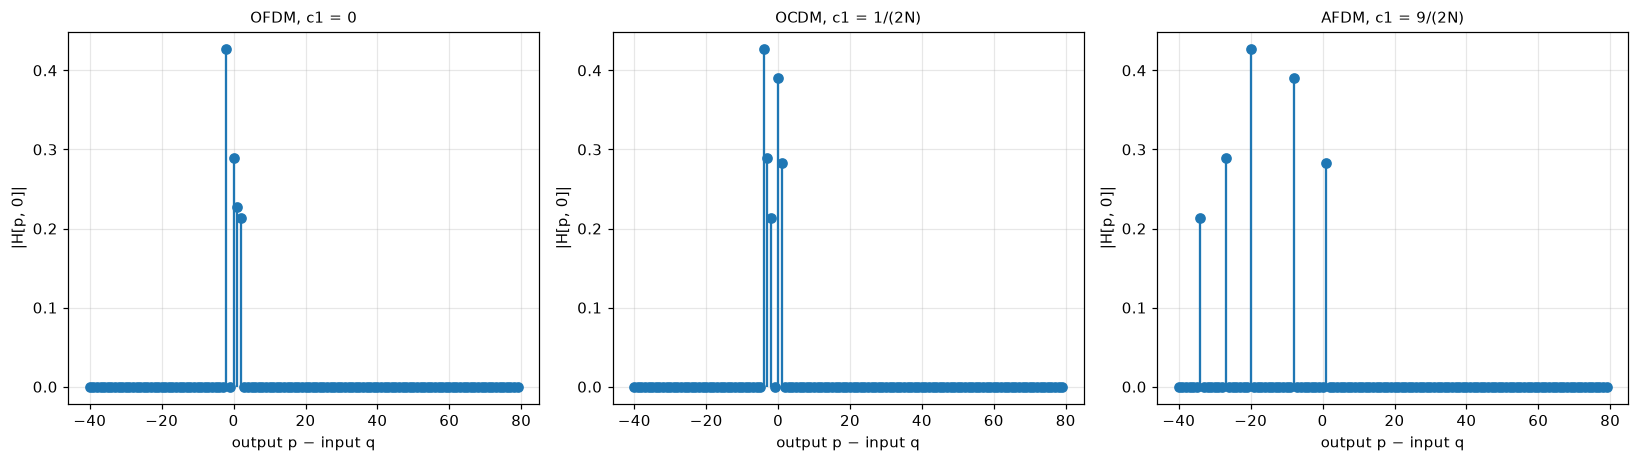

AFDM formula: path (l, α) shifts a symbol by (α − 2N·c1·l) mod N (the sign follows our e^(+j2πνt) convention); with c1 = 9/(2N) that is α − 9·l: different delays do not overlap while |α| ≤ α_max + ξ


In [5]:
pth = draw_paths(np.random.default_rng(5), integer=True)
cases = {"OFDM, c1 = 0": 0.0, "OCDM, c1 = 1/(2N)": 1 / (2 * N), f"AFDM, c1 = {2*N*C1_OPT:.0f}/(2N)": C1_OPT}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (name, c1) in zip(ax, cases.items()):
    H = eff_matrix(pth, c1)
    col = np.abs(H[:, 0]); col = np.roll(col, 40)
    a.stem(np.arange(-40, 80), col[:120], basefmt=" ")
    a.set_xlabel("output p − input q"); a.set_ylabel("|H[p, 0]|"); a.set_title(name, fontsize=10)
    nz = np.sum(np.abs(H[:, 0]) > 1e-6)
    print(f"{name:22}: nonzeros per column {nz:4d}; path positions " +
          ", ".join(f"(l={l}, α={int(round(nu*N/FS)):+d}) → {int(np.argmax(np.abs(eff_matrix([(1, l, nu)], c1)[:, 0])) + N//2) % N - N//2:+d}" for h, l, nu in pth))
plt.tight_layout(); plt.show()
print(f"AFDM formula: path (l, α) shifts a symbol by (α − 2N·c1·l) mod N (the sign follows our e^(+j2πνt) convention); with c1 = {2*N*C1_OPT:.0f}/(2N) that is α − {2*N*C1_OPT:.0f}·l: different delays do not overlap while |α| ≤ α_max + ξ")

## 4. BER: OFDM, OCDM, AFDM, OTFS on one channel
Uncoded QPSK, LMMSE over the full channel matrix for all four. So OFDM here is already free of the ICI floor (like the "full LMMSE" in section 4 of `otfs_sim`), and the only difference is how each waveform spreads a symbol over the paths. Fractional Doppler, a new channel every frame.

- **OFDM** — the shallowest slope: a symbol lives on one subcarrier and cannot reach the delay diversity.
- **OCDM** — steeper, but $\alpha-l$ collisions take away part of the diversity.
- **AFDM** and **OTFS** — practically one curve. Both waveforms separate all the paths and give the detector full diversity.

This confirms the result of Bemani et al.: AFDM matches OTFS in BER, while the frame is one-dimensional and the modem is an OFDM modem with two diagonal chirp multiplications.

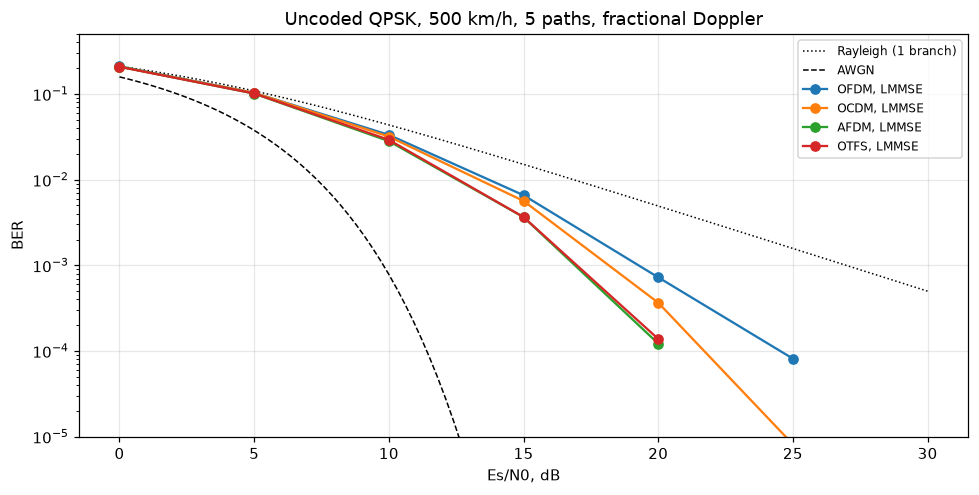

30 channels in 95 s
OFDM : BER at 15 / 20 / 25 dB = 6.6e-03 / 7.2e-04 / 8.1e-05
OCDM : BER at 15 / 20 / 25 dB = 5.6e-03 / 3.7e-04 / 8.1e-06
AFDM : BER at 15 / 20 / 25 dB = 3.7e-03 / 1.2e-04 / 0.0e+00
OTFS : BER at 15 / 20 / 25 dB = 3.7e-03 / 1.4e-04 / 0.0e+00


In [6]:
# OTFS 64×16 on the same channel (a minimal modem from otfs_sim)
Mo, No = 64, 16
def otfs_mod(x, cp=L_CP):
    s = (np.fft.ifft(x.reshape(x.shape[:-1] + (Mo, No)), axis=-1) * np.sqrt(No)).swapaxes(-1, -2).reshape(x.shape)
    return np.concatenate([s[..., -cp:], s], -1)
def otfs_demod(r, cp=L_CP):
    Y = r[..., cp:cp + N].reshape(r.shape[:-1] + (No, Mo)).swapaxes(-1, -2)
    return (np.fft.fft(Y, axis=-1) / np.sqrt(No)).reshape(r.shape[:-1] + (N,))
def eff_otfs(paths):
    return otfs_demod(channel(otfs_mod(np.eye(N, dtype=complex)), paths)).T

snrs = np.arange(0, 31, 5)
schemes = {"OFDM": 0.0, "OCDM": 1 / (2 * N), "AFDM": C1_OPT, "OTFS": None}
ber = {k: np.zeros(len(snrs)) for k in schemes}
t0 = time.time()
for f in range(FRAMES):
    pth = draw_paths(rng)
    for k, c1 in schemes.items():
        H = eff_otfs(pth) if c1 is None else eff_matrix(pth, c1)
        b, x = qpsk_bits(2, N, rng)
        for i, snr in enumerate(snrs):
            n0 = 10 ** (-snr / 10)
            y = x @ H.T + np.sqrt(n0) * crandn(x.shape, rng)
            ber[k][i] += np.mean(hard_bits(lmmse(H, y, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
fig, a = plt.subplots(figsize=(9, 4.6))
sg = np.linspace(0, 30, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Rayleigh (1 branch)")
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for i, k in enumerate(schemes):
    ok = ber[k] > 0
    a.semilogy(snrs[ok], ber[k][ok], f"C{i}o-", label=f"{k}, LMMSE")
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, dB"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"Uncoded QPSK, {SPEED_KMH} km/h, {P_PATHS} paths, fractional Doppler")
plt.tight_layout(); plt.show()
print(f"{FRAMES} channels in {time.time()-t0:.0f} s")
for k in schemes:
    print(f"{k:5}: BER at 15 / 20 / 25 dB = {ber[k][3]:.1e} / {ber[k][4]:.1e} / {ber[k][5]:.1e}")

## 5. An embedded pilot in a one-dimensional frame
One pilot at position 0. Its response is a window of 9 samples per delay, $2Nc_1l_\max+2(\alpha_\max+\xi)+1$ samples in total. The guard is that plus the same on the other side, so that data does not leak in: 89 of 1024 symbols, **8.7 %** (in `otfs_sim` the OTFS guard is whole delay rows across all Dopplers, 14 %). For each delay $l$ and Doppler $\alpha$ in the window, the receiver takes sample $y[\alpha-9l]$ and, if it is above $3\sigma$, adds a "virtual" path $(l,\alpha)$ with that coefficient.

- **Integer Doppler**: the estimate is practically perfect, and BER matches perfect CSI.
- **Fractional Doppler**: each path spreads across its window as a Dirichlet kernel (the margin $\xi=2$ exists for exactly this), the "integer paths" model is inaccurate, and BER hits a floor of ~$4\cdot10^{-2}$. This is the same problem as in OTFS 1.0 (section 5 of `otfs_sim`). The literature handles it by estimating the fractional part of the Doppler (grid search, ML) or with a larger $\xi$. Zak-OTFS (`zak_sim`) handles it through the choice of pulse.

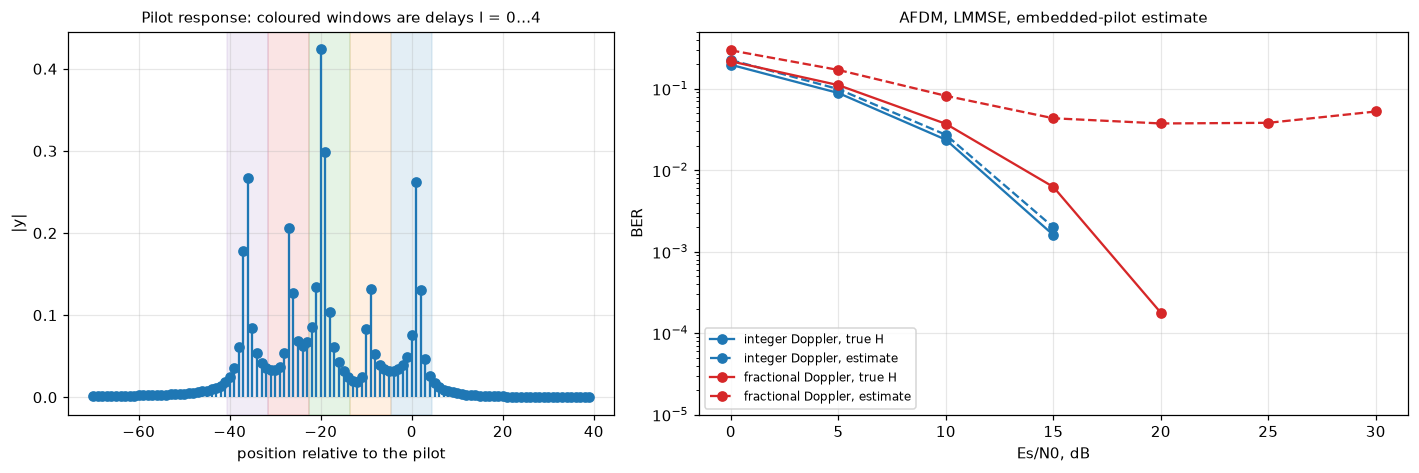

AFDM guard: 89 of 1024 symbols = 8.7% (OTFS in otfs_sim: 14 %); pilot +19.5 dB
  SNR  0: int_true 2.0e-01  int_est 2.3e-01  frac_true 2.2e-01  frac_est 3.0e-01
  SNR  5: int_true 8.9e-02  int_est 9.9e-02  frac_true 1.1e-01  frac_est 1.7e-01
  SNR 10: int_true 2.4e-02  int_est 2.7e-02  frac_true 3.7e-02  frac_est 8.2e-02
  SNR 15: int_true 1.6e-03  int_est 2.0e-03  frac_true 6.2e-03  frac_est 4.3e-02
  SNR 20: int_true 0.0e+00  int_est 0.0e+00  frac_true 1.8e-04  frac_est 3.7e-02
  SNR 25: int_true 0.0e+00  int_est 0.0e+00  frac_true 0.0e+00  frac_est 3.8e-02
  SNR 30: int_true 0.0e+00  int_est 0.0e+00  frac_true 0.0e+00  frac_est 5.3e-02


In [7]:
# embedded pilot in a one-dimensional AFDM frame (Bemani et al.)
Q = A_MAX + XI
PILOT = 0
G = 2 * N * C1_OPT                                            # shift per delay sample
guard = np.zeros(N, bool)
span = int(G * L_MAX + Q)                                     # pilot response: positions −span … Q
guard[(PILOT + np.arange(-span - Q, span + Q + 1)) % N] = True
DATA = ~guard; XP = np.sqrt(guard.sum())

def estimate(y, n0, thr=3.0):
    """For each delay l, read the Doppler window α ∈ [−Q, Q] at position PILOT + α − G·l and build H from the "virtual" paths (l, α) above the threshold."""
    He = np.zeros((N, N), complex)
    for l in range(L_MAX + 1):
        for al in range(-Q, Q + 1):
            pos = int(PILOT + al - G * l) % N
            if abs(y[pos]) > thr * np.sqrt(n0):
                Hb = BASIS[(l, al)]
                He += y[pos] / (XP * Hb[pos, PILOT]) * Hb
    return He

BASIS = {(l, al): eff_matrix([(1.0, l, al * FS / N)], C1_OPT) for l in range(L_MAX + 1) for al in range(-Q, Q + 1)}
snrs5 = np.arange(0, 31, 5)
r5 = {k: np.zeros(len(snrs5)) for k in ("int_true", "int_est", "frac_true", "frac_est")}
for f in range(FRAMES // 2):
    for integer, tag in ((True, "int"), (False, "frac")):
        pth = draw_paths(rng, integer); H = eff_matrix(pth, C1_OPT)
        b, xd = qpsk_bits(1, N, rng); x = xd[0] * DATA; x[PILOT] = XP
        for i, snr in enumerate(snrs5):
            n0 = 10 ** (-snr / 10); y = H @ x + np.sqrt(n0) * crandn(N, rng)
            He = estimate(y, n0)
            for Hd, kk in ((H, "true"), (He, "est")):
                z = lmmse(Hd[:, DATA], (y - Hd[:, PILOT] * XP)[None], n0)[0]
                r5[f"{tag}_{kk}"][i] += np.mean(hard_bits(z) != b[0, DATA])
r5 = {k: v / (FRAMES // 2) for k, v in r5.items()}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
pth = draw_paths(np.random.default_rng(9)); H = eff_matrix(pth, C1_OPT)
e = np.zeros(N, complex); e[PILOT] = 1
resp = np.abs(np.roll(H @ e, span + 30))[:span + 30 + 40]
ax[0].stem(np.arange(-span - 30, 40), resp, basefmt=" ")
for l in range(L_MAX + 1):
    ax[0].axvspan(-G * l - Q - 0.5, -G * l + Q + 0.5, color=f"C{l}", alpha=0.12)
ax[0].set_xlabel("position relative to the pilot"); ax[0].set_ylabel("|y|")
ax[0].set_title(f"Pilot response: coloured windows are delays l = 0…{L_MAX}", fontsize=10)
for k, c, ls, lab in (("int_true", "C0", "-", "integer Doppler, true H"), ("int_est", "C0", "--", "integer Doppler, estimate"),
                      ("frac_true", "C3", "-", "fractional Doppler, true H"), ("frac_est", "C3", "--", "fractional Doppler, estimate")):
    ok = r5[k] > 0
    ax[1].semilogy(snrs5[ok], r5[k][ok], c + "o", ls=ls, label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, dB"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("AFDM, LMMSE, embedded-pilot estimate", fontsize=10)
plt.tight_layout(); plt.show()
print(f"AFDM guard: {guard.sum()} of {N} symbols = {guard.mean():.1%} (OTFS in otfs_sim: 14 %); pilot +{10*np.log10(XP**2):.1f} dB")
for i, snr in enumerate(snrs5):
    print(f"  SNR {snr:2d}: " + "  ".join(f"{k} {v[i]:.1e}" for k, v in r5.items()))

## Comparison: OFDM, OCDM, AFDM, OTFS
| | OFDM | OCDM | AFDM | OTFS |
|---|---|---|---|---|
| Basis | tones | chirps, slope 1/N | chirps, slope $2c_1$ tuned to Doppler | the $M\times N$ DD lattice |
| Frame | 1-D, $N$ | 1-D, $N$ | 1-D, $N$ | 2-D, $M\times N$ |
| Modem | IFFT | $F^H\Gamma F$ | $\Lambda_{c_1}^HF^H\Lambda_{c_2}^H$ — OFDM + 2 diagonals | ISFFT + OFDM |
| Shift of path $(l,\alpha)$ | $\alpha$ | $\alpha-l$ | $\alpha-2Nc_1l$ | $(l,\alpha)$ on the lattice |
| Diversity (LMMSE/MP) | 1 per symbol | partial | full | full |
| Prefix | CP per symbol | CP | CPP (= CP for integer $2Nc_1$) | CP per frame |
| Pilot guard (here) | — | — | 8.7 % | 14 % |
| Fractional Doppler | ICI | ICI | an estimation floor, eased by $\xi$ | an estimation floor (not for Zak-OTFS) |
| OFDM compatibility | — | high | high: the same FFTs | a precoder on top |

AFDM is interesting as an evolutionary path: the modem is OFDM with two extra diagonal multiplications, and $c_1$ is a parameter that can change from frame to frame to match the speed. With $c_1=0$ it is OFDM again. The last notebook in the series, **OTSM/ODDM**, explores another route to simplification: a single carrier in DD.

## Things to try
- `XI = 0` — a smaller $c_1$ and narrower delay windows. Integer Doppler does not suffer, but fractional Doppler in section 5 leaks between windows and the estimation floor rises
- `SPEED_KMH = 1500` — $\alpha_\max=6$, and $c_1$ grows automatically ($2Nc_1=17$); AFDM and OTFS in section 4 stay together
- `P_PATHS = 2` — less diversity: all four curves move closer
- in section 4 add a scheme with a below-optimal $c_1$ (e.g. `"AFDM-": 3 / (2 * N)`) — the windows overlap, and the slope drops to OCDM's level
- in section 2 set `c1f = C1_OPT` — a plain CP is exact again because $2Nc_1$ is an integer